In [1]:
employees = [ {"id": 1, "name": "Arun", "department": "Sales", "salary": 30000, "city": "Chennai"}, {"id": 2, "name": "Priya", "department": "HR", "salary": 45000, "city": "Chennai"}, {"id": 3, "name": "Rahul", "department": "IT", "salary": 60000, "city": "Bangalore"}, {"id": 4, "name": "Divya", "department": "IT", "salary": 75000, "city": "Chennai"}, {"id": 5, "name": "Karthik", "department": "Finance", "salary": 90000, "city": "Mumbai"}, {"id": 6, "name": "Meena", "department": "Sales", "salary": 52000, "city": "Bangalore"}, {"id": 7, "name": "Suresh", "department": "IT", "salary": 68000, "city": "Chennai"}, {"id": 8, "name": "Anitha", "department": "HR", "salary": 48000, "city": "Mumbai"} ]

In [2]:
import pandas as pd

df = pd.DataFrame(employees)
df.to_csv("employees.csv", index=False)

In [3]:

print(df.describe(include='all'))

print("First row with loc:\n", df.loc[0])
print(
    "First 2 rows with iloc:\n", df.iloc[:2]
)

print(
    df[
        (df["department"] == "IT")
        & (df["city"] == "Chennai")
    ]
)

             id  name department        salary     city
count   8.00000     8          8      8.000000        8
unique      NaN     8          4           NaN        3
top         NaN  Arun         IT           NaN  Chennai
freq        NaN     1          3           NaN        4
mean    4.50000   NaN        NaN  58500.000000      NaN
std     2.44949   NaN        NaN  18913.336187      NaN
min     1.00000   NaN        NaN  30000.000000      NaN
25%     2.75000   NaN        NaN  47250.000000      NaN
50%     4.50000   NaN        NaN  56000.000000      NaN
75%     6.25000   NaN        NaN  69750.000000      NaN
max     8.00000   NaN        NaN  90000.000000      NaN
First row with loc:
 id                  1
name             Arun
department      Sales
salary          30000
city          Chennai
Name: 0, dtype: object
First 2 rows with iloc:
    id   name department  salary     city
0   1   Arun      Sales   30000  Chennai
1   2  Priya         HR   45000  Chennai
   id    name department  

In [4]:
import pandas as pd

departments_data = [
    {"department": "Sales", "head": "Vikram", "budget": 500000},
    {"department": "HR", "head": "Ananya", "budget": 350000},
    {"department": "IT", "head": "Karthik", "budget": 900000},
    {"department": "Finance", "head": "Meera", "budget": 700000},
    {"department": "Marketing", "head": "Rohan", "budget": 300000},
]

dept_df = pd.DataFrame(departments_data)
dept_df.to_csv("departments.csv", index=False)
print("departments.csv created.")



departments.csv created.


In [5]:
import pandas as pd

In [6]:



emp_df = pd.read_csv("employees.csv")
dept_df = pd.read_csv(
    "departments.csv"
)


merged_df = dept_df.merge(emp_df, on="department", how="left")

# Missing values 
merged_df["salary"] = (
    merged_df["salary"].fillna(0).astype(int)
)
merged_df["name"] = merged_df["name"].fillna(
    "No Employee"
)

print(merged_df)


  department     head  budget   id         name  salary       city
0      Sales   Vikram  500000  1.0         Arun   30000    Chennai
1      Sales   Vikram  500000  6.0        Meena   52000  Bangalore
2         HR   Ananya  350000  2.0        Priya   45000    Chennai
3         HR   Ananya  350000  8.0       Anitha   48000     Mumbai
4         IT  Karthik  900000  3.0        Rahul   60000  Bangalore
5         IT  Karthik  900000  4.0        Divya   75000    Chennai
6         IT  Karthik  900000  7.0       Suresh   68000    Chennai
7    Finance    Meera  700000  5.0      Karthik   90000     Mumbai
8  Marketing    Rohan  300000  NaN  No Employee       0        NaN


In [7]:


dept_summary = (
    merged_df.groupby("department")
    .agg(
        headcount=("id", "count"),
        total_salary=("salary", "sum"),
        avg_salary=("salary", "mean"),
    )
    .reset_index()
)

print(dept_summary)

  department  headcount  total_salary    avg_salary
0    Finance          1         90000  90000.000000
1         HR          2         93000  46500.000000
2         IT          3        203000  67666.666667
3  Marketing          0             0      0.000000
4      Sales          2         82000  41000.000000


In [8]:
import matplotlib.pyplot as plt

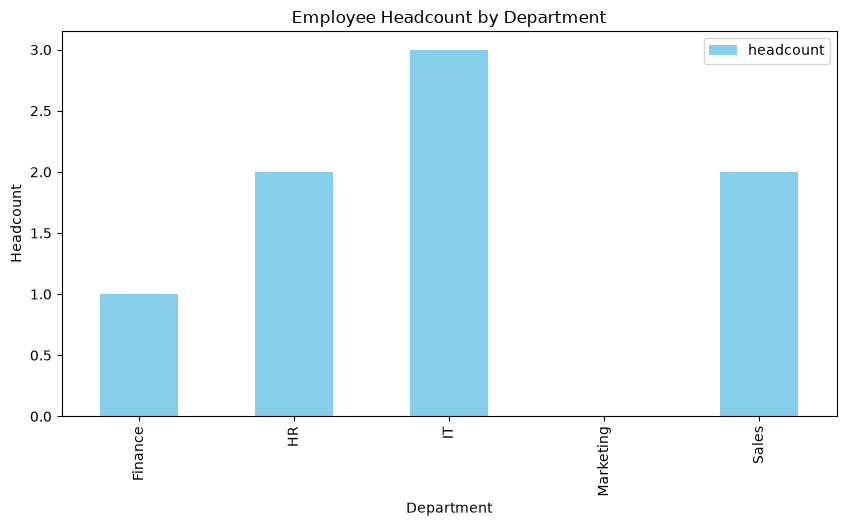

In [10]:




dept_summary.plot(
    x="department",
    y="headcount",
    kind="bar",
    figsize=(10, 5),
    color="skyblue",
)
plt.title("Employee Headcount by Department")
plt.xlabel("Department")
plt.ylabel("Headcount")
plt.show()